# Everpure | Phase 2 survival analysis

**Methodology proof and assumed account scenarios, as of 2026-10-09.** The extract has no reactivation events, event timestamps, or censoring endpoints. The Cox model below is fitted only to synthetic event histories. Account probabilities are assumption based and uncalibrated.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from everpure_case.source_integrity import verify_authoritative_source
from everpure_case.phase2_pipeline import run_pipeline
from everpure_case.survival import exponential_event_probability
from everpure_case.survival_synthetic import (
    BASELINE_HAZARD, FOLLOWUP_MONTHS, generate_synthetic_cohort, fit_synthetic_cox)
from everpure_case.reactivation_scenarios import load_phase1_accounts, load_assumptions, engineer_features
plt.style.use('seaborn-v0_8-whitegrid')
OUT = ROOT / 'outputs/phase2'
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
source_integrity = verify_authoritative_source(ROOT)
metrics = run_pipeline(ROOT)
display(source_integrity)

{'source_sha256': '6863ea0014f050355bf9e0c5166e2284edfe8521ea3d87a2a2fa168177a229bc',
 'source_rows': 2000,
 'raw_recorded_spend_usd': '2541024291'}

## 1. Research question and data limits

We ask for the probability of reactivation within a future horizon from a defined prediction origin. This supplied extract contains account characteristics only. Its booking dates are deterministic functions of account IDs and cannot be reactivation events or event durations.

## 2. Phase 1 integrity and cohort reconciliation

The approved source SHA is checked before Phase 1 outputs are read. The primary 1,144 accounts have source-reported inactivity of at least two years. Their two-fiscal-year eligibility remains unconfirmed. The 562 conflicts and 294 unknowns remain in reconciliation.

In [2]:
recon = pd.read_csv(OUT / 'cohort_reconciliation.csv')
display(recon.groupby('scenario_cohort_status', as_index=False).size())
assert len(recon) == 2000 and recon.account_id.is_unique

,scenario_cohort_status,size
0,eligibility_conflict,562
1,eligibility_unknown,294
2,primary_reported_2y,1144


## 3. Synthetic event-history generation

Enrollment is synthetic t=0; one month is a continuous simulation unit. Exponential event times and independent censoring times are generated with seed 20261009. The model receives only the observed minimum and event flag; simulated truth is excluded from the fitting table.

In [3]:
synthetic = generate_synthetic_cohort()
display(synthetic[['synthetic_subject_id','duration_months','event_observed',
                   'health_proxy','engagement_proxy','partner_proxy']].head())
display(pd.read_json(OUT / 'synthetic_generation_manifest.json', typ='series'))

,synthetic_subject_id,duration_months,event_observed,health_proxy,engagement_proxy,partner_proxy
0,SYN_00000,12.540438,1,0,0.845038,1
1,SYN_00001,30.226886,1,0,0.702957,1
2,SYN_00002,14.457101,1,1,0.140822,1
3,SYN_00003,35.713225,1,0,0.039520,0
4,SYN_00004,22.974235,1,1,-0.259142,0


baseline_hazard_per_month                                                   0.035
censoring                       independent Uniform(8,48) months capped at 36 ...
covariates                      health_proxy~Bernoulli(.4); engagement_proxy~N...
duration_max_months                                                          36.0
duration_median_months                                                  11.973233
duration_min_months                                                      0.000256
event_fraction                                                            0.67125
events                                                                       1074
month_definition                                  continuous simulation time unit
provenance                                                  SYNTHETIC_METHODOLOGY
right_censored                                                                526
seed                                                                     20261009
study_origin    

## 4. Kaplan–Meier estimate on synthetic subjects

The step curve is an empirical estimate within the synthetic experiment. Right-censored subjects contribute time at risk until their censoring point.

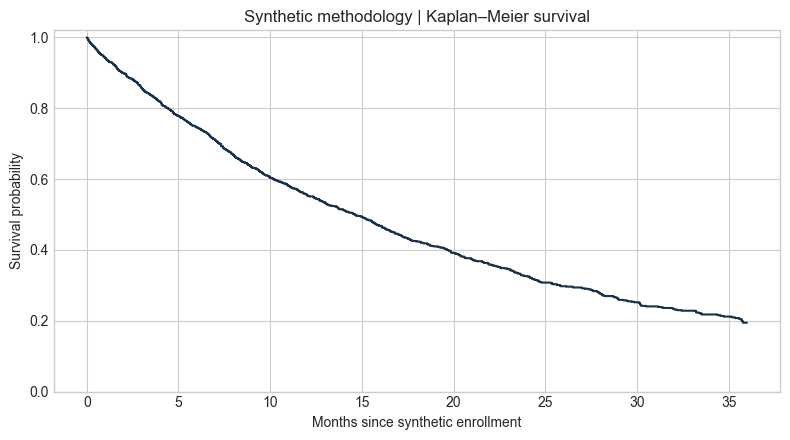

In [4]:
km = pd.read_csv(OUT / 'synthetic_kaplan_meier.csv')
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.step(km.duration_months, km.survival_probability, where='post', color='#17324d')
ax.set(xlabel='Months since synthetic enrollment', ylabel='Survival probability',
       title='Synthetic methodology | Kaplan–Meier survival')
ax.set_ylim(0, 1.02)
fig.tight_layout(); fig.savefig(FIG / 'synthetic_kaplan_meier.png', dpi=160); plt.show(); plt.close(fig)

## 5. Cox fit and hazard-ratio interpretation

Partial likelihood estimates relative hazard effects without specifying a baseline hazard. Lifelines' reported baseline survival is evaluated at its mean covariate profile, not at the all-zero profile. Absolute survival predictions use the fitted baseline survival. A hazard ratio of 1.5 means 1.5 times the instantaneous hazard, not 50% cumulative probability.

,covariate,true_generating_coefficient,estimated_log_hazard_coefficient,estimated_hazard_ratio,hazard_ratio_ci_lower_95,hazard_ratio_ci_upper_95
0,health_proxy,0.45,0.505338,1.657546,1.469690,1.869415
1,engagement_proxy,-0.35,-0.359806,0.697812,0.656154,0.742114
2,partner_proxy,0.25,0.220535,1.246744,1.105786,1.405669


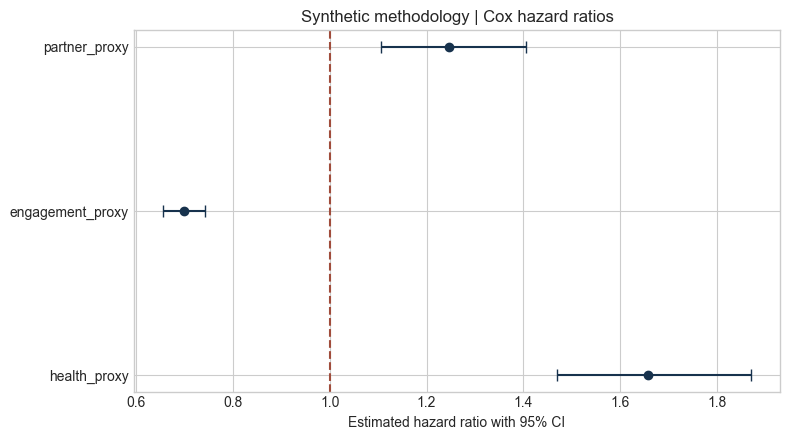

In [5]:
model, coefficients, diagnostics, predictions = fit_synthetic_cox(synthetic)
display(coefficients[['covariate','true_generating_coefficient',
                      'estimated_log_hazard_coefficient','estimated_hazard_ratio',
                      'hazard_ratio_ci_lower_95','hazard_ratio_ci_upper_95']])
fig, ax = plt.subplots(figsize=(8, 4.5))
y = np.arange(len(coefficients))
hr = coefficients.estimated_hazard_ratio.to_numpy()
ax.errorbar(hr, y, xerr=[hr-coefficients.hazard_ratio_ci_lower_95.to_numpy(),
                         coefficients.hazard_ratio_ci_upper_95.to_numpy()-hr],
            fmt='o', color='#17324d', capsize=4)
ax.axvline(1, color='#a04c3b', linestyle='--')
ax.set(yticks=y, yticklabels=coefficients.covariate,
       xlabel='Estimated hazard ratio with 95% CI',
       title='Synthetic methodology | Cox hazard ratios')
fig.tight_layout(); fig.savefig(FIG / 'synthetic_hazard_ratios.png', dpi=160); plt.show(); plt.close(fig)

## 6. Diagnostics and censoring

The rank-transformed Schoenfeld test checks time variation in fitted effects. A small p-value would be reported rather than silently selecting another seed. Concordance is shown separately for the fitting sample and an independent synthetic holdout; neither validates Everpure predictions.

In [6]:
display(diagnostics)
assert diagnostics['n_events'] + diagnostics['n_right_censored'] == len(synthetic)

{'provenance': 'SYNTHETIC_METHODOLOGY',
 'converged': True,
 'fit_status': 'converged',
 'warnings': [],
 'convergence_warnings': [],
 'numerical_warnings': [],
 'ph_schoenfeld_rank_p_values': {'engagement_proxy': 0.2523688837220447,
  'health_proxy': 0.28328716869220194,
  'partner_proxy': 0.939195015702955},
 'ph_rejections_at_0_05': [],
 'concordance_in_sample': 0.6238576893605554,
 'concordance_independent_synthetic_holdout': 0.5953205167830871,
 'baseline_survival_monotone': True,
 'baseline_survival_at_last_event': 0.17979382368764188,
 'baseline_survival_reference_profile': 'lifelines mean covariate profile',
 'n_events': 1074,
 'n_right_censored': 526}

## 7. Synthetic Cox survival curves

These absolute curves combine estimated relative effects with the synthetic baseline survival. Profiles are invented and are not Everpure accounts.

,synthetic_profile,survival_at_36_months
0,lifelines mean covariates,0.179794
1,fitted all-zero covariates,0.284609
2,true generating all-zero,0.283654


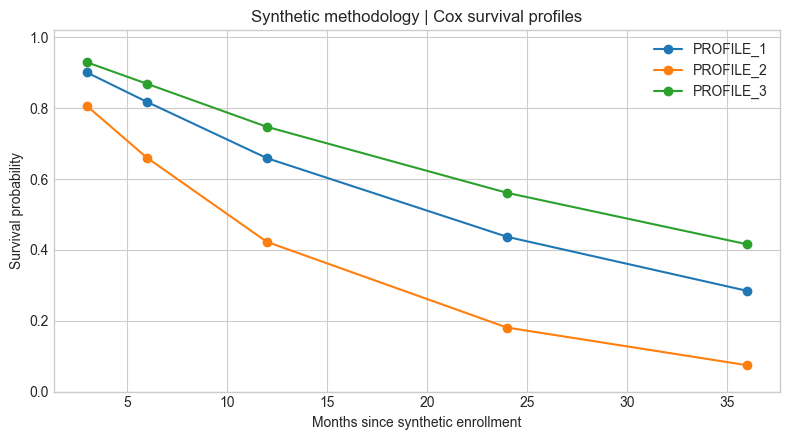

In [7]:
pred = pd.read_csv(OUT / 'synthetic_survival_predictions.csv')
baseline_comparison = pd.DataFrame([{
    'synthetic_profile': 'lifelines mean covariates',
    'survival_at_36_months': diagnostics['baseline_survival_at_last_event']}, {
    'synthetic_profile': 'fitted all-zero covariates',
    'survival_at_36_months': pred.loc[(pred.synthetic_profile_id=='PROFILE_1') &
                                      (pred.horizon_months==36), 'survival_probability'].iloc[0]}, {
    'synthetic_profile': 'true generating all-zero',
    'survival_at_36_months': np.exp(-BASELINE_HAZARD*FOLLOWUP_MONTHS)}])
display(baseline_comparison)
fig, ax = plt.subplots(figsize=(8, 4.5))
for profile, group in pred.groupby('synthetic_profile_id'):
    ax.plot(group.horizon_months, group.survival_probability, marker='o', label=profile)
ax.set(xlabel='Months since synthetic enrollment', ylabel='Survival probability',
       title='Synthetic methodology | Cox survival profiles')
ax.set_ylim(0, 1.02); ax.legend()
fig.tight_layout(); fig.savefig(FIG / 'synthetic_cox_survival.png', dpi=160); plt.show(); plt.close(fig)

## 8. Everpure assumed hazard parameters

The origin is the frozen 2026-10-09 analysis date, a modeling convention rather than an actual campaign start. The constant monthly baseline hazards and common feature effects below are chosen assumptions. They are independent of the synthetic Cox coefficients.

In [8]:
assumptions = load_assumptions(ROOT)
display(assumptions)
accounts = load_phase1_accounts(ROOT)
features = engineer_features(accounts)
display(features[['health_unknown','partner_unknown','tickets_missing','ticket_sentinel']].sum())

{'version': 'phase2-assumptions-v1',
 'provenance': 'ASSUMPTION_BASED_NOT_CALIBRATED',
 'analysis_as_of_date': '2026-10-09',
 'time_unit': 'continuous_month',
 'cohort_policy': 'reported_2y_scenario_cohort',
 'horizons_months': [3, 6, 12],
 'monthly_baseline_hazards': {'conservative': 0.006,
  'base': 0.012,
  'optimistic': 0.02},
 'assumed_log_hazard_effects': {'health_red': -0.35,
  'health_yellow': -0.15,
  'partner_managed_yes': 0.15,
  'log1p_valid_tickets': -0.08,
  'is_child': -0.1},
 'missing_feature_contribution': 'reference-level assumed contribution with explicit missingness flags',
 'rationale': 'Illustrative monthly hazards and modest directional effects chosen for transparent sensitivity analysis; no Everpure event histories or external conversion benchmarks were used.'}

health_unknown     844
partner_unknown    654
tickets_missing    322
ticket_sentinel    322
dtype: int64

## 9. Account-level cumulative probabilities

For each account: P(T≤t)=1−exp[−baseline hazard × t × exp(assumed linear predictor)]. These are conditional scenario inputs, not fitted propensities.

,profile,base_12_month_assumed_probability
0,"Hypothetical Red, managed, child, one valid ti...",0.095998


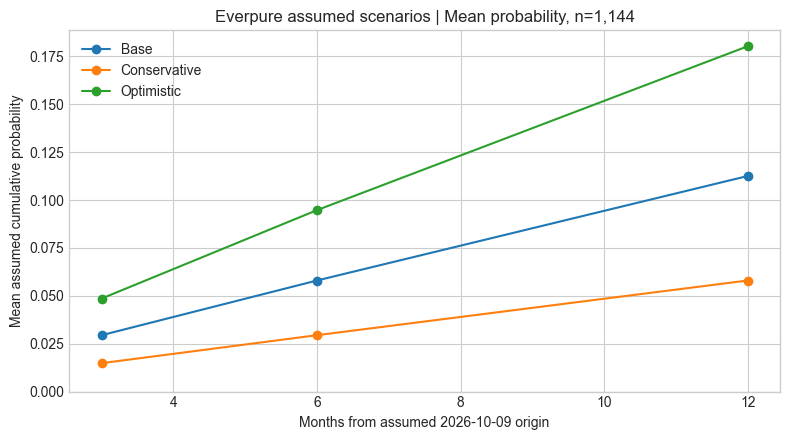

In [9]:
detail = pd.read_csv(OUT / 'reactivation_scenario_probabilities.csv')
effects = assumptions['assumed_log_hazard_effects']
hypothetical_eta = (effects['health_red'] + effects['partner_managed_yes'] +
                    effects['log1p_valid_tickets']*np.log1p(1) + effects['is_child'])
display(pd.DataFrame([{'profile': 'Hypothetical Red, managed, child, one valid ticket',
                       'base_12_month_assumed_probability': float(
                           exponential_event_probability(
                               assumptions['monthly_baseline_hazards']['base'], 12,
                               hypothetical_eta))}]))
curves = detail.groupby(['scenario_name','horizon_months'], as_index=False)[
    'cumulative_reactivation_probability'].mean()
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, group in curves.groupby('scenario_name'):
    ax.plot(group.horizon_months, group.cumulative_reactivation_probability,
            marker='o', label=name.title())
ax.set(xlabel='Months from assumed 2026-10-09 origin',
       ylabel='Mean assumed cumulative probability',
       title='Everpure assumed scenarios | Mean probability, n=1,144')
ax.set_ylim(bottom=0); ax.legend()
fig.tight_layout(); fig.savefig(FIG / 'assumed_probability_curves.png', dpi=160); plt.show(); plt.close(fig)

## 10. Expected reactivations

The expected count is the sum of account-level probabilities for the stated denominator. Linearity of expectation does not require independent accounts. These counts are not observed conversions, causal uplift, incremental revenue, or NPV.

,scenario_name,horizon_months,cohort_accounts,expected_reactivations,mean_probability
0,base,3,1144,33.672239,0.029434
1,base,6,1144,66.329653,0.057980
2,base,12,1144,128.724044,0.112521
3,conservative,3,1144,16.964965,0.014830
4,conservative,6,1144,33.672239,0.029434
5,conservative,12,1144,66.329653,0.057980
6,optimistic,3,1144,55.554657,0.048562
7,optimistic,6,1144,108.348134,0.094710
8,optimistic,12,1144,206.205025,0.180249


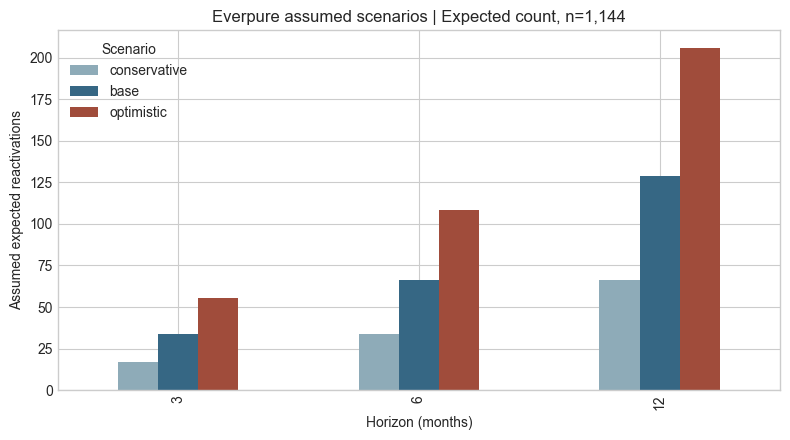

In [10]:
summary = pd.read_csv(OUT / 'reactivation_scenario_summary.csv')
display(summary[['scenario_name','horizon_months','cohort_accounts',
                 'expected_reactivations','mean_probability']])
wide = summary.pivot(index='horizon_months', columns='scenario_name',
                     values='expected_reactivations')
ax = wide[['conservative','base','optimistic']].plot.bar(figsize=(8, 4.5),
    color=['#8eabb8','#366784','#a04c3b'])
ax.set(xlabel='Horizon (months)', ylabel='Assumed expected reactivations',
       title='Everpure assumed scenarios | Expected count, n=1,144')
ax.legend(title='Scenario')
fig = ax.figure
fig.tight_layout(); fig.savefig(FIG / 'assumed_expected_counts.png', dpi=160); plt.show(); plt.close(fig)

## 11. Assumption and cohort sensitivity

Hazard, effect, and missing-health choices keep the 1,144-account denominator fixed. The observed-average health effect weights the chosen Green/Yellow/Red contributions by their observed frequencies among known-health accounts in the primary cohort. Expanded cohorts hypothetically add the disputed and then unknown accounts, changing the denominator. Mean probability and expected count are shown together to distinguish propensity from population effects.

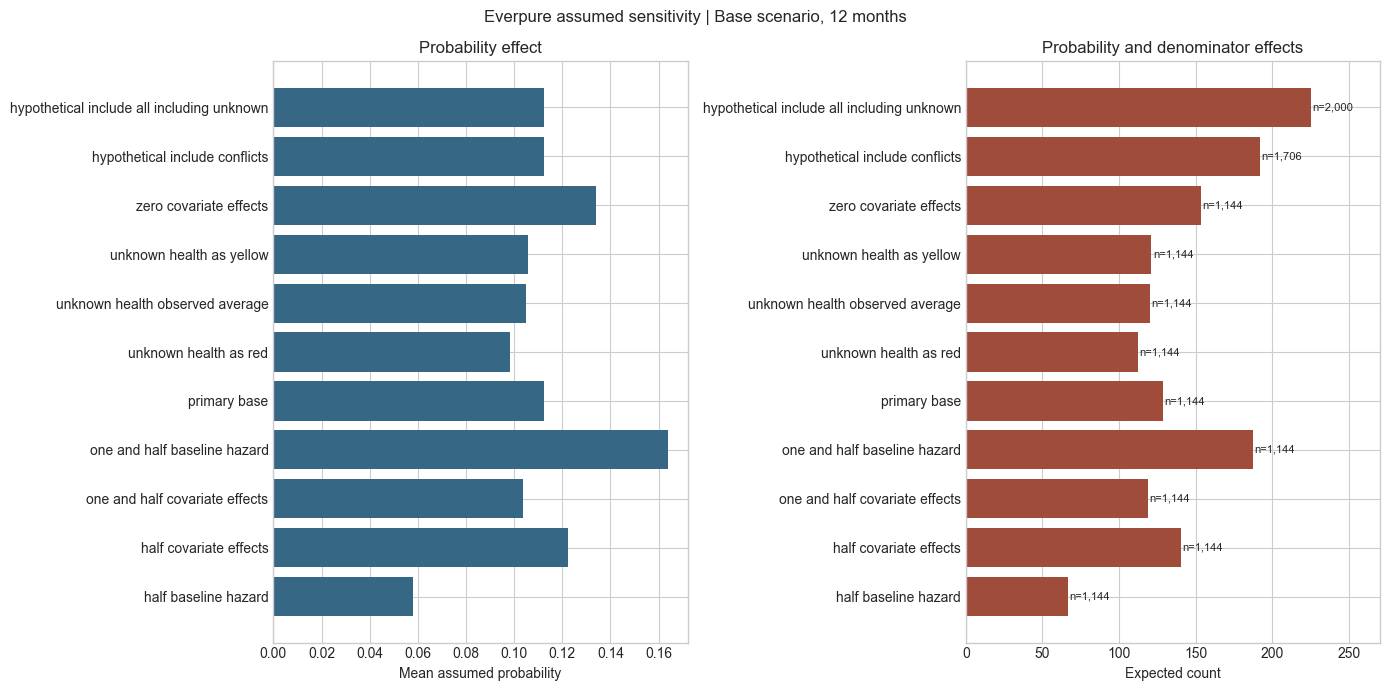

,sensitivity_case,cohort_accounts,mean_probability,expected_reactivations
2,half_baseline_hazard,1144,0.057980,66.329653
5,half_covariate_effects,1144,0.122550,140.196735
17,one_and_half_covariate_effects,1144,0.103818,118.768248
14,one_and_half_baseline_hazard,1144,0.163830,187.421612
20,primary_base,1144,0.112521,128.724044
23,unknown_health_as_red,1144,0.098229,112.374350
29,unknown_health_observed_average,1144,0.105131,120.269458
26,unknown_health_as_yellow,1144,0.105849,121.090877
32,zero_covariate_effects,1144,0.134112,153.424416
11,hypothetical_include_conflicts,1706,0.112476,191.883767


In [11]:
sensitivity = pd.read_csv(OUT / 'scenario_sensitivity.csv')
s12 = sensitivity[sensitivity.horizon_months.eq(12)].sort_values('cohort_accounts')
labels = s12.sensitivity_case.str.replace('_', ' ', regex=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].barh(labels, s12.mean_probability, color='#366784')
axes[0].set(xlabel='Mean assumed probability', title='Probability effect')
axes[1].barh(labels, s12.expected_reactivations, color='#a04c3b')
axes[1].set(xlabel='Expected count', title='Probability and denominator effects')
axes[1].set_xlim(0, s12.expected_reactivations.max()*1.20)
for y, n in enumerate(s12.cohort_accounts):
    axes[1].text(s12.expected_reactivations.iloc[y]+1, y, f'n={n:,}', va='center', fontsize=8)
fig.suptitle('Everpure assumed sensitivity | Base scenario, 12 months')
fig.tight_layout(); fig.savefig(FIG / 'assumed_sensitivity.png', dpi=160); plt.show(); plt.close(fig)
display(s12[['sensitivity_case','cohort_accounts','mean_probability','expected_reactivations']])

## 12. Business interpretation and limits

All output applies to the supplied 2,000-row extract and the explicitly selected 1,144-account provisional cohort. True Everpure reactivation hazard, calibration, treatment effect, fiscal eligibility, and financial value are unidentified. Root-group dependence may affect total-count uncertainty, but no uncertainty interval is inferred from this extract.

## 13. Phase 3 interface

`reactivation_scenario_probabilities.csv` is the only account-level probability input. Its versioned JSON contract states grain, provenance, source hash, horizon, cohort policy, and reconciliation. Phase 3 must supply separate financial assumptions and must not treat these assumed probabilities as observed conversion evidence.

In [12]:
import json
contract = json.loads((OUT / 'phase3_input_contract.json').read_text(encoding='utf-8'))
display(contract)
assert contract['expected_rows'] == len(detail)
assert detail.probability_provenance.eq(contract['probability_provenance']).all()

{'account_identifier': 'account_id',
 'account_identifier_provenance': 'OBSERVED_SOURCE',
 'analysis_as_of_date': '2026-10-09',
 'artifact': 'outputs/phase2/reactivation_scenario_probabilities.csv',
 'assumption_fingerprint_canonicalization': 'SHA-256 of UTF-8 JSON with sorted keys, compact separators, ensure_ascii=False and no NaN',
 'assumption_fingerprint_sha256': '6195ba2e90c95976ed91b7bdd42509341fd22e71e6b2bb5aed2e5d2a6d346ee7',
 'assumption_register_artifact': 'outputs/phase2/assumptions.json',
 'causal_attribution': {'gross_reactivation_is_incremental_uplift': False,
  'incremental_cash_flow_requires_additional_assumptions': True,
  'observed_treatment_status': False,
  'untreated_counterfactual_available': False,
  'without_counterfactual_valuation_label': 'illustrative gross reactivation economics'},
 'cohort_policy': 'reported_2y_scenario_cohort',
 'cohort_status': 'primary_reported_2y',
 'event_semantics': {'coherent_first_event_time': 'May be sampled from the assumed consta